# Гибридная система рекомендаций книг с нейросетевым ранжировщиком (Goodbooks-10k)

Итоговый проект развивает ДЗ №1 (`notebook.ipynb`): там были реализованы и сравнены Popularity,
Content (TF-IDF), Item-CF, SVD и PureSVD. Здесь эти модели становятся **базовым уровнем** гибридной
системы, поверх которого строятся признаки, пул кандидатов, ранжировщики и слой разнообразия.

Весь код вынесен в пакет [`src/bookrec`](src/bookrec): ноутбук только вызывает его и показывает
анализ. Благодаря этому тот же код запускается как сквозной пайплайн (`run_pipeline.py`).

План:
0. Данные и протокол оценки (повторяют ДЗ, чтобы метрики были сравнимы)
1. Базовые модели из ДЗ: воспроизведение метрик
2. Расширенные признаки пользователей, книг и взаимодействий
3. Пул кандидатов: объединение выдач всех моделей
4. Гибрид: взвешенное смешивание, обучаемый ранжировщик, MMR-разнообразие
5. Нейросетевой ранжировщик и его интеграция
6. Сравнительный анализ, сегменты, выводы
7. Сквозной пайплайн

In [1]:
import sys, time, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bookrec import Config
from bookrec.data import build_dataset
from bookrec.models import fit_all_models
from bookrec.metrics import Evaluator, metric_columns
from bookrec.features import book_features, user_features, GENRES
from bookrec.candidates import CandidateGenerator, feature_columns, SCORE_MODELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40, "display.width", 160)
BLUE, GRAY, GREEN = "#4C72B0", "#999999", "#55A868"

cfg = Config()
cfg

Config(data_dir='goodsbooks-10k', artifacts_dir='artifacts', seed=42, test_frac=0.2, relevant_threshold=4, n_eval_users=3000, n_tune_users=2000, n_fit_users=6000, k_list=(5, 10), top_tags_per_book=30, itemcf_k=20, itemcf_shrink=50.0, pure_svd_factors=500, funk_svd_params={'n_factors': 10, 'reg_all': 0.1, 'n_epochs': 30, 'random_state': 42}, popularity_min_ratings=50, pool_per_model=50, n_genres_user_profile=16, nn_hidden=(128, 64), nn_epochs=15, nn_lr=0.001, nn_batch_size=2048, nn_dropout=0.2)

## Этап 0. Данные и протокол оценки

Повторяем протокол ДЗ, иначе новые метрики нельзя будет сравнивать со старыми:
- дубликаты пар (user, book) удалены, пустые `original_title` заполнены;
- **train/test = 80/20 внутри каждого пользователя** (времени оценок в данных нет);
- релевантная книга = оценка **≥ 4** в тесте; кандидаты = все книги, не оценённые в train;
- три непересекающиеся выборки пользователей:
  - `eval_users` (3 000, seed 42) — итоговые метрики, те же люди, что в ДЗ;
  - `tune_users` (2 000, seed 7) — подбор весов гибрида и гиперпараметров;
  - `fit_users` (6 000, seed 11) — **новая** выборка для обучения ранжировщиков второго уровня.

Зачем три выборки: ранжировщик учится на тестовых метках `fit_users`, веса подбираются на
`tune_users`, а итог считается на `eval_users`. Ни одна тестовая метка `eval_users` не
используется до финального сравнения, поэтому утечки нет.

In [2]:
t = time.time()
ds = build_dataset(cfg)
print(f"{time.time() - t:.1f}s")
pd.Series(ds.summary(), name="count").to_frame()

6.1s


,count
ratings,979478
users,53424
books,10000
train,784517
test,194961
users_with_relevant_test,37968
eval_users,3000
tune_users,2000
fit_users,6000


## Этап 1. Базовые модели из ДЗ

Пять моделей приведены к одному интерфейсу: `score_user(user_id)` возвращает скор для **всех
10 000 книг в едином порядке** (`ds.item_ids`). Это ключевое соглашение проекта: раз порядок
общий, скоры разных моделей можно стандартизировать, складывать и подавать в ранжировщик без
маппинга идентификаторов. В ДЗ каждая модель жила со своим индексом, и именно это мешало их объединить.

| Модель | Что делает | Как ранжирует |
|---|---|---|
| `popularity` | байесовский рейтинг (формула IMDb) | одинаково для всех |
| `content` | TF-IDF по названию + тегам; профиль = средний вектор понравившихся книг | косинус к профилю |
| `itemcf` | adjusted cosine + shrinkage по оценкам | «сила доказательств» Σ sim·(r − r̄ᵤ) |
| `funk_svd` | surprise.SVD, явные оценки, 10 факторов, reg 0.1 | предсказанная оценка |
| `pure_svd` | усечённое SVD неявной матрицы «понравилось», 500 факторов | m_u V Vᵀ |

Обученные модели кэшируются в `artifacts/models/`, повторный запуск занимает секунды.

In [3]:
t = time.time()
models = fit_all_models(ds, cache_dir=cfg.artifacts_path / "models")
print(f"{time.time() - t:.1f}s")

  [popularity] ... 

ok
  [content] ... 

ok
  [itemcf] ... 

ok
  [funk_svd] ... 

ok
  [pure_svd] ... 

ok
0.2s


In [4]:
ev = Evaluator(ds, k_list=cfg.k_list)
t = time.time()
for name, m in models.items():
    ev.evaluate(name, m.recommender())
print(f"{time.time() - t:.0f}s")

HW_REF = pd.Series({"popularity": 0.002, "content": 0.129, "itemcf": 0.137, "funk_svd": 0.001, "pure_svd": 0.163},
                   name="nDCG@10 в ДЗ")
base_summary = ev.summary(content_model=models["content"]).join(HW_REF)
base_summary.style.format("{:.4f}").background_gradient(subset=metric_columns(cfg.k_list), cmap="Greens")

popularity                       P@10=0.0006  R@10=0.0019  nDCG@10=0.0011


content                          P@10=0.0454  R@10=0.1680  nDCG@10=0.1293


itemcf                           P@10=0.0524  R@10=0.1486  nDCG@10=0.1372


funk_svd                         P@10=0.0005  R@10=0.0010  nDCG@10=0.0008


pure_svd                         P@10=0.0684  R@10=0.1930  nDCG@10=0.1625
113s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,ILD,nDCG@10 в ДЗ
model,,,,,,,,,,
popularity,0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,0.7093,0.0020
content,0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,0.5799,0.1290
itemcf,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,0.7947,0.1370
funk_svd,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.6437,0.0010
pure_svd,0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,0.7093,0.1630


Метрики совпали с ДЗ до третьего знака (столбец «nDCG@10 в ДЗ»), значит перенос в пакет корректен.
Добавилась колонка **ILD** (intra-list diversity): 1 − средняя попарная TF-IDF-близость книг внутри
выдачи. У Content она ожидаемо самая низкая: он рекомендует «больше того же самого».

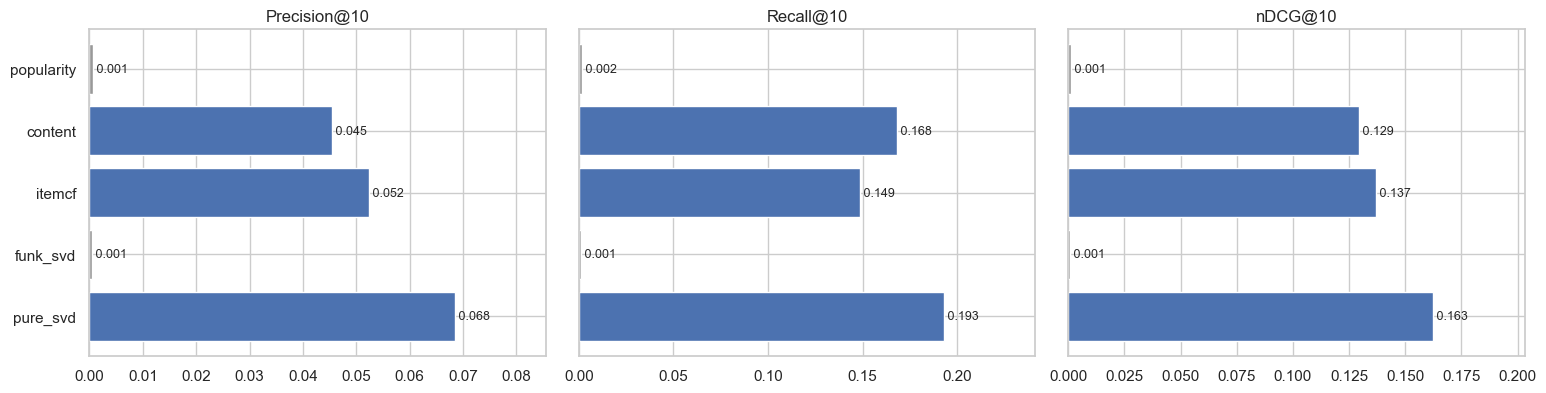

In [5]:
def plot_metrics(summary, cols=("Precision@10", "Recall@10", "nDCG@10"), highlight=()):
    fig, axes = plt.subplots(1, len(cols), figsize=(5.2 * len(cols), 0.5 * len(summary) + 1.6), sharey=True)
    for ax, col in zip(axes, cols):
        vals = summary[col]
        colors = [GREEN if any(h in m for h in highlight) else (GRAY if m in ("popularity", "funk_svd", "random") else BLUE)
                  for m in vals.index]
        ax.barh(vals.index, vals.values, color=colors)
        for y, v in enumerate(vals.values):
            ax.text(v, y, f" {v:.3f}", va="center", fontsize=9)
        ax.set_title(col); ax.set_xlim(0, vals.max() * 1.25)
    axes[0].invert_yaxis()
    plt.tight_layout(); plt.show()

plot_metrics(base_summary)

In [6]:
seg = ev.by_segment("nDCG@10")
print("Пользователей в сегментах:", ev.per_user.drop_duplicates("user_id")["segment"].value_counts().to_dict())
seg.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens")

Пользователей в сегментах: {'средние (6-20)': 1317, 'активные (>20)': 852, 'холодные (≤5)': 831}


segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
popularity,0.0004,0.0010,0.0020
content,0.1242,0.1306,0.1322
itemcf,0.0611,0.1417,0.2044
funk_svd,0.0003,0.0005,0.0016
pure_svd,0.0964,0.1490,0.2480


**Напоминание из ДЗ, важное для гибрида.** Для холодных пользователей (≤ 5 оценок) лучше всех
Content, для активных (> 20) заметно лучше PureSVD. Popularity и FunkSVD на уровне случайного
угадывания: первый из-за обрезанной выборки (≈100 оценок на книгу), второй потому, что оптимизирует
RMSE, а не ранжирование. Тем не менее обе модели остаются в системе: их скоры станут **признаками**
для ранжировщика, и он сам решит, когда они полезны.

## Этап 2. Расширенные признаки

Все признаки считаются **только по train** и по метаданным книг. Три группы
(код в [`features.py`](src/bookrec/features.py) и [`candidates.py`](src/bookrec/candidates.py)):

**Признаки книги (`b_*`)**
- популярность и качество по train: число оценок, среднее, разброс, доля «понравилось», байесовский рейтинг;
- популярность на Goodreads (`ratings_count`, `average_rating`, разброс по `ratings_1..5`): здесь виден
  настоящий длинный хвост, которого нет в обрезанном `ratings.csv`;
- год издания, признак серии (`#` в названии), число книг автора в каталоге;
- **18 жанровых категорий** из тегов: доля «голосов» топ-30 тегов книги, попавших в жанр (мягкий профиль).

**Признаки пользователя (`u_*`)**
- активность (число оценок, log), средняя оценка и её разброс, доля высоких оценок;
- «строгость» = средняя оценка пользователя минус средний рейтинг книг, которые он читал (аналог bᵤ);
- мейнстримность вкуса (средняя log-популярность прочитанного), средний год, доля серий;
- жанровый профиль = средний жанровый вектор понравившихся книг, и его **энтропия** (разнообразие вкуса).

**Признаки взаимодействия (`x_*`, `s_*`, `rank_*`)**
- z-скор и ранг книги в выдаче **каждой** из пяти моделей, число моделей, предложивших книгу (`n_votes`);
- максимальная близость книги к прочитанному в трёх пространствах: TF-IDF, Item-CF, PureSVD;
- совпадение автора с любимыми / прочитанными книгами; косинус жанрового профиля и жанра книги;
- насколько книга популярнее, новее и выше по рейтингу, чем привык пользователь.

In [7]:
book_feats = book_features(ds, models["content"], models["popularity"])
user_feats = user_features(ds, book_feats)
print("book_features:", book_feats.shape, " user_features:", user_feats.shape)
book_feats.drop(columns=[c for c in book_feats.columns if c.startswith("b_genre_")]).describe().T[["mean", "std", "min", "max"]].round(3)

book_features: (10000, 29)  user_features: (53424, 30)


,mean,std,min,max
b_n_ratings,78.452,5.904,6.000,95.000
b_mean_rating,3.856,0.306,1.916,4.814
b_std_rating,0.934,0.125,0.456,1.797
b_share_high,0.662,0.130,0.042,0.987
b_bayes_rating,3.855,0.146,2.897,4.311
b_log_gr_ratings,10.185,0.937,7.907,15.380
b_gr_avg_rating,4.002,0.254,2.470,4.820
b_gr_std_proxy,0.944,0.099,0.518,1.522
b_year,1991.654,36.461,1800.000,2017.000
b_is_series,0.444,0.497,0.000,1.000


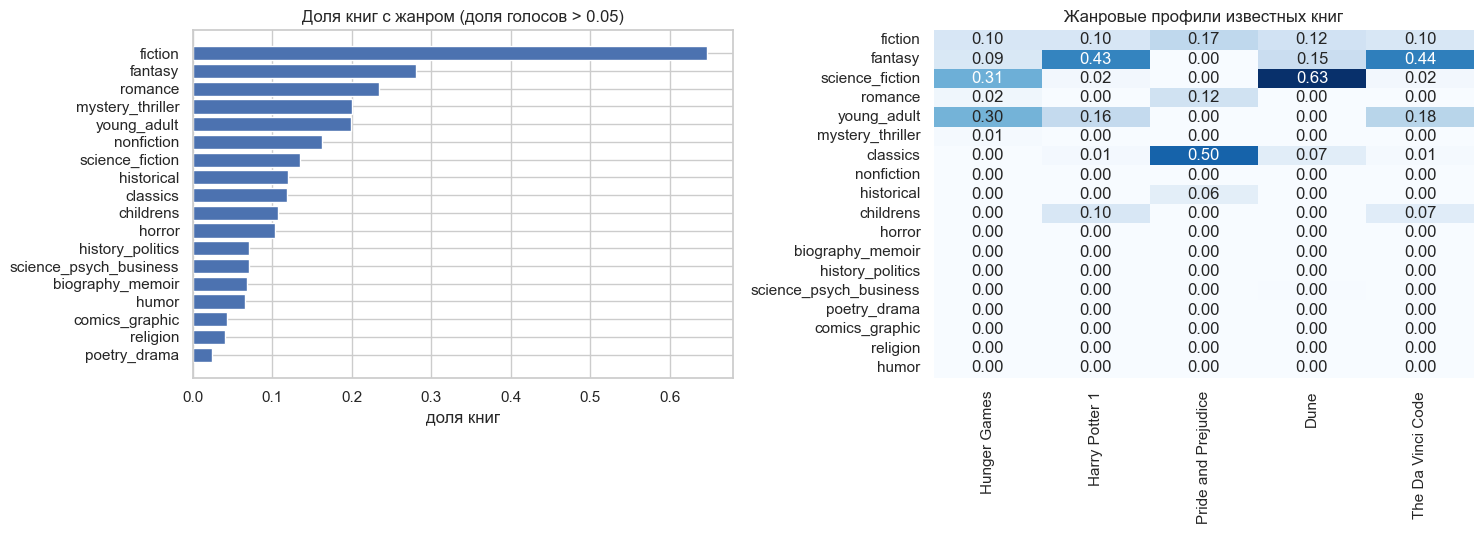

In [8]:
# Жанры: сколько книг попадает в каждую категорию и пример для известных книг
gcols = [f"b_genre_{g}" for g in GENRES]
share = (book_feats[gcols] > 0.05).mean().sort_values(ascending=False)
share.index = [c.replace("b_genre_", "") for c in share.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(share.index[::-1], share.values[::-1], color=BLUE)
axes[0].set_title("Доля книг с жанром (доля голосов > 0.05)"); axes[0].set_xlabel("доля книг")

examples = {1: "Hunger Games", 2: "Harry Potter 1", 10: "Pride and Prejudice", 126: "Dune", 25: "The Da Vinci Code"}
ex = book_feats.loc[list(examples), gcols].T
ex.columns = list(examples.values()); ex.index = [c.replace("b_genre_", "") for c in ex.index]
sns.heatmap(ex, ax=axes[1], cmap="Blues", annot=True, fmt=".2f", cbar=False)
axes[1].set_title("Жанровые профили известных книг")
plt.tight_layout(); plt.show()

Жанровые профили осмысленны: «Голодные игры» = science_fiction + young_adult, «Гарри Поттер» = fantasy
+ childrens, «Гордость и предубеждение» = classics + romance, «Дюна» = science_fiction, «Код да Винчи» =
mystery_thriller. Это даёт ранжировщику то, чего нет ни у одной модели ДЗ: явное понимание, в каком
жанре пользователь читает и подходит ли ему книга по жанру.

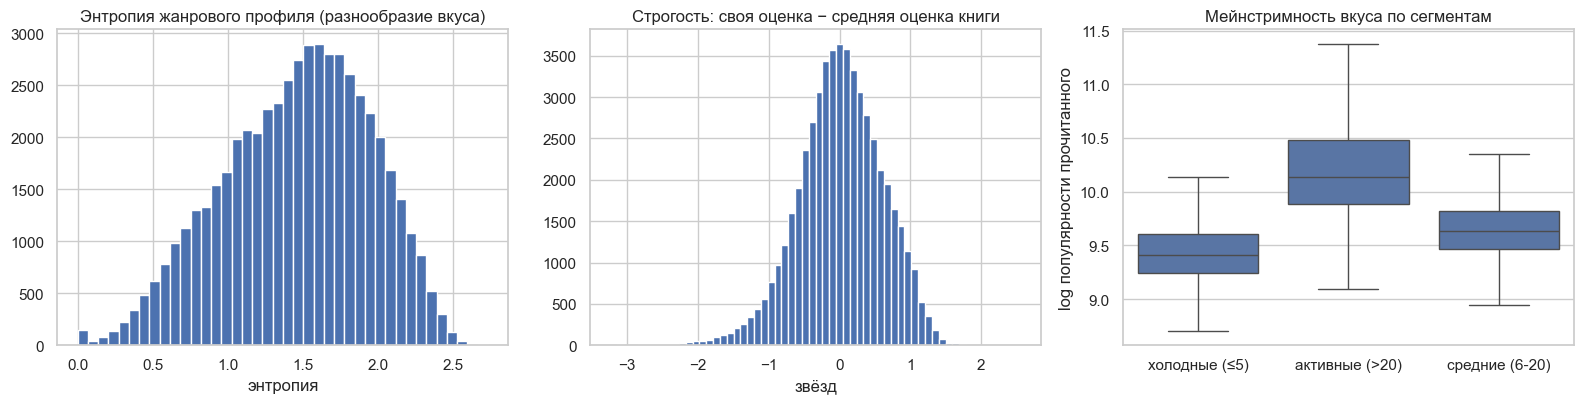

In [9]:
# Признаки пользователей: распределения и связь с активностью
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(user_feats["u_taste_entropy"], bins=40, color=BLUE)
axes[0].set_title("Энтропия жанрового профиля (разнообразие вкуса)"); axes[0].set_xlabel("энтропия")
axes[1].hist(user_feats["u_strictness"], bins=60, color=BLUE)
axes[1].set_title("Строгость: своя оценка − средняя оценка книги"); axes[1].set_xlabel("звёзд")
sns.boxplot(x=user_feats["u_segment"].map({0: "холодные (≤5)", 1: "средние (6-20)", 2: "активные (>20)"}),
            y=user_feats["u_mean_book_pop"], ax=axes[2], color=BLUE, showfliers=False)
axes[2].set_title("Мейнстримность вкуса по сегментам"); axes[2].set_xlabel(""); axes[2].set_ylabel("log популярности прочитанного")
plt.tight_layout(); plt.show()

**Что видно.** Разнообразие вкуса распределено широко: есть читатели одного жанра (энтропия ≈ 0) и
всеядные. Строгость симметрична вокруг нуля с заметными хвостами: есть люди, которые системно
ставят на звезду ниже или выше, чем остальные тем же книгам. Активные пользователи читают **менее**
мейнстримные книги, чем холодные: с ростом числа прочитанного вкус уходит в хвост каталога. Это
аргумент в пользу разных стратегий для сегментов.

## Этап 3. Пул кандидатов

Ранжировщик второго уровня дорого применять ко всем 10 000 книгам для каждого пользователя. Вместо
этого каждая базовая модель отдаёт свой top-50 непрочитанных книг, выдачи объединяются в **пул
кандидатов**, и уже внутри него считаются признаки и происходит ранжирование. Прочитанные книги
отфильтрованы ещё на уровне моделей.

Главный вопрос к пулу: **какую долю релевантных книг он вообще содержит**. Это верхняя граница
recall любого гибрида.

57s, пользователей: 1000


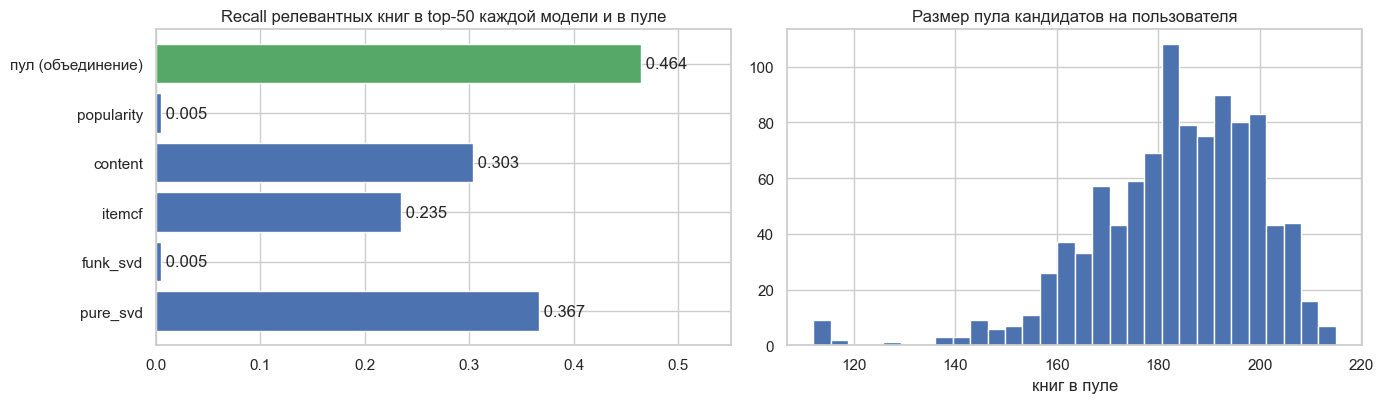

Средний размер пула: 183 из 250 возможных


In [10]:
gen = CandidateGenerator(ds, models, book_feats, user_feats, pool_per_model=cfg.pool_per_model)

t = time.time()
pool_stats = gen.pool_recall(ds.tune_users[:1000])
print(f"{time.time() - t:.0f}s, пользователей: {len(pool_stats)}")

rec_cols = ["recall_pool"] + [f"recall_{g}" for g in SCORE_MODELS]
pr = pool_stats[rec_cols].mean()
pr.index = ["пул (объединение)"] + list(SCORE_MODELS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].barh(pr.index[::-1], pr.values[::-1], color=[BLUE] * 5 + [GREEN])
for y, v in enumerate(pr.values[::-1]):
    axes[0].text(v, y, f" {v:.3f}", va="center")
axes[0].set_title("Recall релевантных книг в top-50 каждой модели и в пуле"); axes[0].set_xlim(0, 0.55)
axes[1].hist(pool_stats["pool_size"], bins=30, color=BLUE)
axes[1].set_title("Размер пула кандидатов на пользователя"); axes[1].set_xlabel("книг в пуле")
plt.tight_layout(); plt.show()
print(f"Средний размер пула: {pool_stats['pool_size'].mean():.0f} из {5 * cfg.pool_per_model} возможных")

**Что видно.**
- Пул покрывает заметно больше релевантных книг, чем лучшая одиночная модель: выдачи моделей
  **дополняют** друг друга, а не дублируют. Средний размер пула ≈ 185 из 250 возможных, то есть
  пересечение выдач небольшое.
- Popularity и FunkSVD в пул почти ничего полезного не приносят (recall < 1%): их top-50 одинаков для
  всех пользователей. В гибриде они будут полезны только как признаки «качества книги», а не как
  источники кандидатов.
- Recall пула ≈ 0.45 означает, что больше половины релевантных книг **ни одна** модель не ставит в
  свой top-50. Это естественная граница: оценки в тесте случайные 20% прочитанного, часть из них
  непредсказуема в принципе.

In [11]:
# Таблица признаков для обучения ранжировщика: fit_users, метка = релевантна ли книга в тесте.
# Построение занимает ~6 минут, поэтому результат кэшируется в artifacts/.
pool_path = cfg.artifacts_path / "train_pool.parquet"
t = time.time()
if pool_path.exists():
    train_pool = pd.read_parquet(pool_path)
    print("loaded from cache")
else:
    train_pool = gen.build_many(ds.fit_users, verbose=False)
    train_pool.to_parquet(pool_path)
print(f"{time.time() - t:.0f}s  ->  {train_pool.shape[0]:,} пар (user, book), {len(feature_columns(train_pool))} признаков")
print(f"Доля положительных меток: {train_pool['label'].mean():.3%}")
train_pool.head(3)

loaded from cache
3s  ->  1,102,092 пар (user, book), 79 признаков
Доля положительных меток: 0.922%


,user_id,book_id,s_popularity,rank_popularity,s_content,rank_content,s_itemcf,rank_itemcf,s_funk_svd,rank_funk_svd,s_pure_svd,rank_pure_svd,n_votes,x_content_max_sim,x_itemcf_max_sim,x_puresvd_max_sim,x_same_author,x_author_read,x_genre_match,x_pop_vs_user,...,b_author_n_books,b_genre_fiction,b_genre_fantasy,b_genre_science_fiction,b_genre_romance,b_genre_young_adult,b_genre_mystery_thriller,b_genre_classics,b_genre_nonfiction,b_genre_historical,b_genre_childrens,b_genre_horror,b_genre_biography_memoir,b_genre_history_politics,b_genre_science_psych_business,b_genre_poetry_drama,b_genre_comics_graphic,b_genre_religion,b_genre_humor,label
0,34832,192,2.390942,3.951244,-0.299813,8.279190,-0.018422,6.536692,2.888852,2.944439,-0.517327,9.009692,1.0,0.000000,0.0,-0.010988,0.0,0.0,0.000000,3.312672,...,3.0,0.085331,0.76853,0.06297,0.0,0.004722,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0
1,34832,247,-1.554794,9.142704,10.097220,2.079442,-0.018422,6.612041,-1.460903,9.130864,1.151929,6.259582,1.0,0.450519,0.0,0.046869,1.0,1.0,0.975148,3.072575,...,4.0,0.000000,0.00000,0.00000,0.0,0.000000,0.0,0.000000,0.232906,0.0,0.0,0.0,0.0,0.0,0.393759,0.0,0.0,0.0,0.0,0
2,34832,260,-0.845558,8.999619,7.738640,3.871201,-0.018422,6.629363,-0.654961,8.932344,-0.030686,8.376321,1.0,0.348318,0.0,0.001232,0.0,0.0,0.406542,2.965069,...,2.0,0.000000,0.00000,0.00000,0.0,0.000000,0.0,0.046087,0.432248,0.0,0.0,0.0,0.0,0.0,0.047925,0.0,0.0,0.0,0.0,0


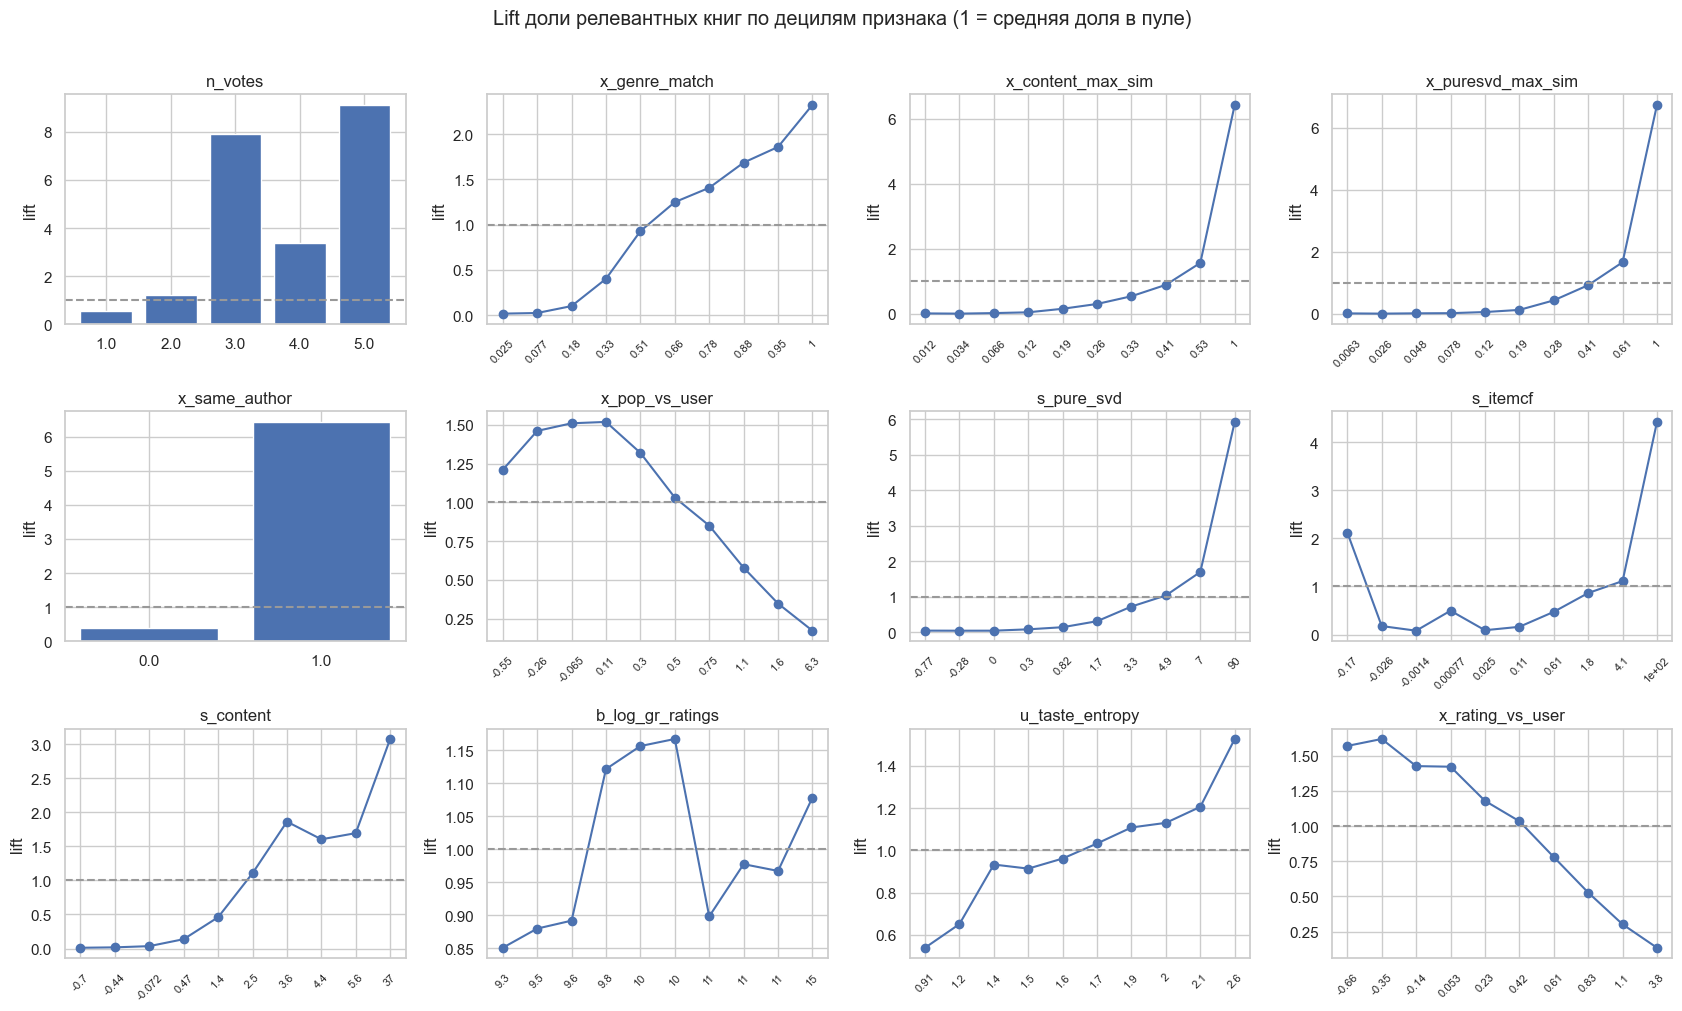

In [12]:
# Насколько признаки «видят» релевантность: средняя метка по бинам признака (lift относительно базовой доли)
base_rate = train_pool["label"].mean()
feats_to_show = ["n_votes", "x_genre_match", "x_content_max_sim", "x_puresvd_max_sim", "x_same_author", "x_pop_vs_user",
                 "s_pure_svd", "s_itemcf", "s_content", "b_log_gr_ratings", "u_taste_entropy", "x_rating_vs_user"]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, f in zip(axes.ravel(), feats_to_show):
    x = train_pool[f]
    if x.nunique() <= 6:
        g = train_pool.groupby(x)["label"].mean()
        ax.bar(g.index.astype(str), g.values / base_rate, color=BLUE)
    else:
        bins = pd.qcut(x, 10, duplicates="drop")
        g = train_pool.groupby(bins, observed=True)["label"].mean()
        ax.plot(range(len(g)), g.values / base_rate, marker="o", color=BLUE)
        ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{iv.right:.2g}" for iv in g.index], rotation=45, fontsize=8)
    ax.axhline(1, ls="--", c=GRAY); ax.set_title(f); ax.set_ylabel("lift")
plt.suptitle("Lift доли релевантных книг по децилям признака (1 = средняя доля в пуле)", y=1.01)
plt.tight_layout(); plt.show()

**Что видно.** Признаки действительно разделяют релевантные и нерелевантные книги в пуле:
- `n_votes`: книга, которую предложили 3+ модели, релевантна в несколько раз чаще, чем предложенная
  одной. Это прямое обоснование гибрида «голосованием».
- Близость к истории (`x_content_max_sim`, `x_puresvd_max_sim`), жанровое совпадение и совпадение
  автора дают монотонный рост lift: чем ближе книга к тому, что человек уже любил, тем выше шанс.
- Скоры коллаборативных моделей (`s_pure_svd`, `s_itemcf`) информативны в верхнем дециле (lift 4–6),
  у Content рост более плавный. У `s_itemcf` есть неожиданный всплеск в самом нижнем дециле: сильно
  отрицательная «сила доказательств» бывает только у активных пользователей, а у них базовая доля
  релевантных книг выше. Это взаимодействие признаков, которое линейная формула не поймает.
- `x_pop_vs_user`: пик lift у книг **с привычным для пользователя уровнем популярности**, а книги
  намного популярнее привычного релевантны в 5 раз реже. Абсолютная популярность (`b_log_gr_ratings`)
  почти не информативна (lift 0.85–1.17): важна не популярность сама по себе, а её соответствие
  привычкам человека.
- `x_rating_vs_user`: книги со средним рейтингом **ниже** собственной средней оценки пользователя
  релевантны чаще. Строгие пользователи читают то, что им нравится, независимо от общего рейтинга.
- `u_taste_entropy`: у «всеядных» читателей кандидаты из пула релевантны чаще, у читателей одного
  жанра реже: их нужный жанр моделями уже исчерпан.

Эти зависимости нелинейны и взаимодействуют между собой, поэтому на следующем этапе их объединит
обучаемый ранжировщик, а не ручная формула.

In [13]:
# Сохраняем таблицы признаков книг и пользователей для пайплайна
book_feats.to_parquet(cfg.artifacts_path / "book_features.parquet")
user_feats.to_parquet(cfg.artifacts_path / "user_features.parquet")
print("saved to", cfg.artifacts_path)

saved to artifacts


---
*Этапы 4–7 (гибрид, нейросетевой ранжировщик, итоговое сравнение, пайплайн) добавляются далее.*